# UrbanPulse Nepal — Unusual Municipality-Month Activity

This notebook uses Isolation Forest to rank unusual municipality-month activity profiles in the BIPAD records. The analysis is retrospective. An anomaly is a record pattern that differs from the patterns represented in this dataset; it is not evidence of an imminent disaster or a forecast.

The unit of analysis is one municipality in one calendar month with at least one mapped incident. Features include the monthly record count relative to that municipality’s observed monthly median, its hazard-ID composition, its calendar month, and its total number of records in the snapshot. Months with zero reported incidents are absent; this limits interpretation. Population and reporting-exposure denominators are not available in this dataset.

## 1. Load processed records and the verified administrative lookup

This notebook reuses the exact BIPAD ward-to-municipality ID mapping saved in notebook 04. It does not join on municipality name. It reports the number of incidents that can be assigned to a municipality and stops if the required fields or lookup are missing.

In [1]:
from pathlib import Path
import ast, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from IPython.display import display

PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'data').is_dir(): PROJECT_ROOT=PROJECT_ROOT.parent
if not (PROJECT_ROOT/'data').is_dir(): raise FileNotFoundError('Run from repository or notebooks/ folder.')
PROCESSED_ROOT=PROJECT_ROOT/'data'/'processed'/'bipad_incidents'
data_dirs=sorted((p for p in PROCESSED_ROOT.iterdir() if (p/'incidents_processed.csv').is_file()),key=lambda p:p.name)
if not data_dirs: raise FileNotFoundError('Run notebooks 01 and 02 first.')
DATA_DIR=data_dirs[-1]
LOOKUP_ROOT=PROJECT_ROOT/'data'/'raw'/'bipad_admin_lookup'
lookup_dirs=sorted((p for p in LOOKUP_ROOT.iterdir() if (p/'ward_to_municipality.csv').is_file()),key=lambda p:p.name)
if not lookup_dirs: raise FileNotFoundError('Run notebook 04 first; saved ward-to-municipality mapping is required.')
LOOKUP_DIR=lookup_dirs[-1]
incidents=pd.read_csv(DATA_DIR/'incidents_processed.csv',low_memory=False)
ward_map=pd.read_csv(LOOKUP_DIR/'ward_to_municipality.csv',dtype={'ward_id':'string','municipality_id':'string'},low_memory=False)
required={'id','wards','incidentOn_nepal','hazard_id'}
if not required.issubset(incidents.columns): raise ValueError(f'Missing incident fields: {sorted(required-set(incidents.columns))}')
if not {'ward_id','municipality_id','municipality_name'}.issubset(ward_map.columns): raise ValueError('Saved administrative lookup lacks required ID fields.')
print('Incident snapshot:',DATA_DIR)
print('Administrative lookup:',LOOKUP_DIR)
print(f'Input incident rows: {len(incidents):,}; lookup rows: {len(ward_map):,}')

Incident snapshot: c:\Projects_Tracking\DisasterLens Nepal\data\processed\bipad_incidents\20261013T101245Z
Administrative lookup: c:\Projects_Tracking\DisasterLens Nepal\data\raw\bipad_admin_lookup\20261013T103410Z
Input incident rows: 64,735; lookup rows: 6,803


## 2. Build municipality-month activity profiles

Incident dates are converted to Nepal time before assigning calendar months. If an incident references several wards, it is counted once per municipality. A monthly baseline is calculated from each municipality’s observed active months only, so the ratio is not a rate per population and must not be interpreted as a risk measure.

In [2]:
def parse_ward_list(value):
    if isinstance(value,list): return value
    if isinstance(value,str):
        try:
            parsed=json.loads(value) if value.lstrip().startswith('[') else ast.literal_eval(value)
            return parsed if isinstance(parsed,(list,tuple)) else []
        except (ValueError,SyntaxError,json.JSONDecodeError): return []
    return []

work=incidents[['id','wards','incidentOn_nepal','hazard_id']].copy()
work['incident_id']=work['id'].astype('string')
work['ward_id_list']=work['wards'].map(parse_ward_list)
work['incident_datetime']=pd.to_datetime(work['incidentOn_nepal'],errors='coerce',utc=True).dt.tz_convert('Asia/Kathmandu')
work['month']=work['incident_datetime'].dt.strftime('%Y-%m')
work=work.dropna(subset=['month'])
work=work.explode('ward_id_list').rename(columns={'ward_id_list':'ward_id'})
work['ward_id']=work['ward_id'].astype('string')
mapped=work.merge(ward_map[['ward_id','municipality_id','municipality_name']].drop_duplicates('ward_id'),on='ward_id',how='inner')
mapped=mapped.drop_duplicates(['incident_id','municipality_id'])
if mapped.empty: raise ValueError('No incidents could be joined to the saved municipality lookup.')
mapped['month_number']=mapped['incident_datetime'].dt.month.astype(int)
mapped['hazard_id']=mapped['hazard_id'].fillna('unknown').astype('string')
municipality_month=mapped.groupby(['municipality_id','municipality_name','month'],as_index=False).agg(incident_count=('incident_id','nunique'),month_number=('month_number','first'))
municipality_month['municipality_total_records']=municipality_month.groupby('municipality_id')['incident_count'].transform('sum')
municipality_month['municipality_active_month_median']=municipality_month.groupby('municipality_id')['incident_count'].transform('median')
municipality_month['count_ratio_to_active_month_median']=municipality_month['incident_count']/municipality_month['municipality_active_month_median'].clip(lower=1)
municipality_month['log_monthly_count']=np.log1p(municipality_month['incident_count'])
municipality_month['log_municipality_total']=np.log1p(municipality_month['municipality_total_records'])
municipality_month['log_count_ratio']=np.log1p(municipality_month['count_ratio_to_active_month_median'])
municipality_month['month_sin']=np.sin(2*np.pi*municipality_month['month_number']/12)
municipality_month['month_cos']=np.cos(2*np.pi*municipality_month['month_number']/12)
hazard_counts=pd.crosstab([mapped['municipality_id'],mapped['month']],mapped['hazard_id'])
hazard_shares=hazard_counts.div(hazard_counts.sum(axis=1),axis=0).add_prefix('hazard_share_').reset_index()
municipality_month=municipality_month.merge(hazard_shares,on=['municipality_id','month'],how='left')
print(f'Incident–municipality pairs: {len(mapped):,}')
print(f'Municipality-month observations with reported incidents: {len(municipality_month):,}')
print(f'Municipalities represented: {municipality_month.municipality_id.nunique():,}')
print('Observed month range:',municipality_month['month'].min(),'to',municipality_month['month'].max())
display(municipality_month.sort_values('incident_count',ascending=False).head(10))

Incident–municipality pairs: 64,735
Municipality-month observations with reported incidents: 28,202
Municipalities represented: 755
Observed month range: 2011-04 to 2026-10


,municipality_id,municipality_name,month,incident_count,month_number,municipality_total_records,municipality_active_month_median,count_ratio_to_active_month_median,log_monthly_count,log_municipality_total,...,hazard_share_23,hazard_share_24,hazard_share_3,hazard_share_4,hazard_share_45,hazard_share_5,hazard_share_6,hazard_share_7,hazard_share_8,hazard_share_9
26511,73002,Alital,2026-09,49,9,317,2.0,24.5,3.912023,5.762051,...,0.000000,0.040816,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0
19732,53004,Rolpa,2026-08,48,8,591,2.0,24.0,3.891820,6.383507,...,0.020833,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0
3594,16007,Golbazar,2026-08,44,8,735,2.0,22.0,3.806662,6.601230,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0
3595,16007,Golbazar,2026-09,44,9,735,2.0,22.0,3.806662,6.601230,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0
26447,73002,Alital,2012-09,43,9,317,2.0,21.5,3.784190,5.762051,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0
17998,5001,Belbari,2023-12,42,12,1315,5.0,8.4,3.761200,7.182352,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0
28045,9005,Khandbari,2026-06,41,6,527,2.0,20.5,3.737670,6.269096,...,0.048780,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0
19731,53004,Rolpa,2026-07,41,7,591,2.0,20.5,3.737670,6.383507,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.02439,0.0
16309,47002,Mathagadhi,2026-09,41,9,418,2.0,20.5,3.737670,6.037871,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0
13211,38009,Rhishing,2026-09,40,9,272,2.0,20.0,3.713572,5.609472,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0


## 3. Fit Isolation Forest settings and compare anomaly behavior

Isolation Forest produces an anomaly score from feature-space isolation. This notebook compares three subsample sizes and contamination thresholds. Contamination sets an approximate fraction of observations the model labels as anomalies; it is not an externally validated true anomaly rate. Scores and labels are relative to the selected data and features.

In [3]:
feature_cols=['log_monthly_count','log_municipality_total','log_count_ratio','month_sin','month_cos']+[c for c in municipality_month.columns if c.startswith('hazard_share_')]
X=municipality_month[feature_cols].replace([np.inf,-np.inf],np.nan).fillna(0).to_numpy(dtype=float)
CONFIGS=[{'max_samples':256,'contamination':0.01},{'max_samples':256,'contamination':0.03},{'max_samples':512,'contamination':0.01},{'max_samples':512,'contamination':0.03},{'max_samples':1024,'contamination':0.01},{'max_samples':1024,'contamination':0.03}]
label_cols=[]; summary=[]
for cfg in CONFIGS:
    name='iforest_samples{}_contam{:02d}pct'.format(cfg['max_samples'],int(cfg['contamination']*100))
    model=IsolationForest(n_estimators=300,max_samples=min(cfg['max_samples'],len(X)),contamination=cfg['contamination'],random_state=42,n_jobs=-1)
    model.fit(X)
    scores=model.decision_function(X)  # Lower values are more anomalous.
    labels=model.predict(X)  # -1 anomaly candidate, +1 inlier under this threshold.
    municipality_month[name+'_score']=scores
    municipality_month[name+'_label']=labels
    label_cols.append(name+'_label')
    candidate_count=int((labels==-1).sum())
    summary.append({'max_samples':cfg['max_samples'],'contamination_setting':cfg['contamination'],'observations':len(X),'candidate_count':candidate_count,'observed_candidate_percent':100*candidate_count/len(X),'score_min':float(scores.min()),'score_median':float(np.median(scores)),'score_max':float(scores.max())})
    print('Finished',name)
comparison=pd.DataFrame(summary)
display(comparison)

# Compare overlap among the 1% candidate sets from each subsample size.
one_pct=[c for c in label_cols if '_contam01pct_label' in c]
for left_idx in range(len(one_pct)):
    for right_idx in range(left_idx+1,len(one_pct)):
        a=set(municipality_month.index[municipality_month[one_pct[left_idx]]==-1]); b=set(municipality_month.index[municipality_month[one_pct[right_idx]]==-1])
        union=a|b; print(f'{one_pct[left_idx]} vs {one_pct[right_idx]}: Jaccard overlap={len(a&b)/len(union):.3f}')

Finished iforest_samples256_contam01pct
Finished iforest_samples256_contam03pct
Finished iforest_samples512_contam01pct
Finished iforest_samples512_contam03pct
Finished iforest_samples1024_contam01pct
Finished iforest_samples1024_contam03pct


,max_samples,contamination_setting,observations,candidate_count,observed_candidate_percent,score_min,score_median,score_max
0,256,0.01,28202,283,1.003475,-0.062289,0.107369,0.161479
1,256,0.03,28202,847,3.003333,-0.089214,0.080444,0.134554
2,512,0.01,28202,283,1.003475,-0.067895,0.104120,0.152904
3,512,0.03,28202,847,3.003333,-0.093127,0.078887,0.127671
4,1024,0.01,28202,283,1.003475,-0.085476,0.097209,0.142691
5,1024,0.03,28202,847,3.003333,-0.104442,0.078242,0.123724


iforest_samples256_contam01pct_label vs iforest_samples512_contam01pct_label: Jaccard overlap=0.742
iforest_samples256_contam01pct_label vs iforest_samples1024_contam01pct_label: Jaccard overlap=0.645
iforest_samples512_contam01pct_label vs iforest_samples1024_contam01pct_label: Jaccard overlap=0.736


## 4. Inspect representative anomaly candidates

Review high-count and low-count candidates separately. The model flags unusual combinations in its chosen feature space; data-entry artifacts, changes in reporting, and genuinely unusual historical activity can all contribute. These rows require human review before any substantive interpretation.

Anomaly candidates under selected display setting: 283 / 28,202
Highest recorded monthly counts among candidates:


,municipality_name,municipality_id,month,incident_count,municipality_active_month_median,count_ratio_to_active_month_median,iforest_samples512_contam01pct_score
26511,Alital,73002,2026-09,49,2.0,24.5,-0.065717
19732,Rolpa,53004,2026-08,48,2.0,24.0,-0.044338
3594,Golbazar,16007,2026-08,44,2.0,22.0,-0.051184
3595,Golbazar,16007,2026-09,44,2.0,22.0,-0.067895
26447,Alital,73002,2012-09,43,2.0,21.5,-0.056303
17998,Belbari,5001,2023-12,42,5.0,8.4,-0.032928
16309,Mathagadhi,47002,2026-09,41,2.0,20.5,-0.058691
19731,Rolpa,53004,2026-07,41,2.0,20.5,-0.039525
28045,Khandbari,9005,2026-06,41,2.0,20.5,-0.037822
13211,Rhishing,38009,2026-09,40,2.0,20.0,-0.064780


Lowest model scores (most isolated in this fitted feature space):


,municipality_name,municipality_id,month,incident_count,municipality_active_month_median,count_ratio_to_active_month_median,iforest_samples512_contam01pct_score
3595,Golbazar,16007,2026-09,44,2.0,22.000000,-0.067895
14079,Barhadashi,4002,2024-09,36,4.0,9.000000,-0.066514
26511,Alital,73002,2026-09,49,2.0,24.500000,-0.065717
13211,Rhishing,38009,2026-09,40,2.0,20.000000,-0.064780
25682,Gauriganga,71005,2026-07,32,3.0,10.666667,-0.063218
16309,Mathagadhi,47002,2026-09,41,2.0,20.500000,-0.058691
10427,Brindaban,32002,2017-08,31,3.0,10.333333,-0.058042
15407,Kushma,44003,2026-09,32,2.0,16.000000,-0.057436
21237,Rapti Sonari,57008,2026-09,33,3.0,11.000000,-0.057328
26447,Alital,73002,2012-09,43,2.0,21.500000,-0.056303


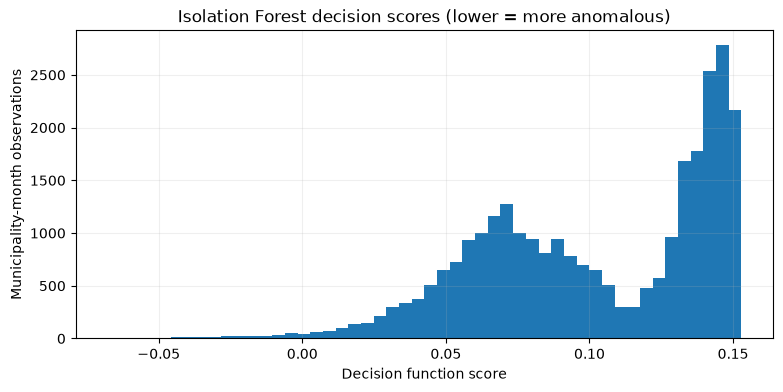

In [4]:
main_score=next(c for c in municipality_month.columns if c.endswith('_score') and 'samples512_contam01pct' in c)
main_label=main_score.replace('_score','_label')
candidates=municipality_month.loc[municipality_month[main_label]==-1].copy()
print(f'Anomaly candidates under selected display setting: {len(candidates):,} / {len(municipality_month):,}')
print('Highest recorded monthly counts among candidates:')
display(candidates.sort_values('incident_count',ascending=False)[['municipality_name','municipality_id','month','incident_count','municipality_active_month_median','count_ratio_to_active_month_median',main_score]].head(15))
print('Lowest model scores (most isolated in this fitted feature space):')
display(candidates.sort_values(main_score)[['municipality_name','municipality_id','month','incident_count','municipality_active_month_median','count_ratio_to_active_month_median',main_score]].head(15))
ax=municipality_month[main_score].hist(bins=50,figsize=(9,4))
ax.set(title='Isolation Forest decision scores (lower = more anomalous)',xlabel='Decision function score',ylabel='Municipality-month observations'); ax.grid(alpha=0.2)


## 5. Save model comparison and candidate records

The saved score and label columns allow candidate review under each tested setting. Candidate labels depend on the selected contamination threshold and do not represent ground-truth classes. No predictive accuracy metrics are calculated because there are no validated anomaly labels.

In [5]:
OUTPUT_DIR=PROJECT_ROOT/'data'/'processed'/'isolation_forest' / DATA_DIR.name
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
comparison_path=OUTPUT_DIR/'isolation_forest_configuration_comparison.csv'
profiles_path=OUTPUT_DIR/'municipality_month_anomaly_scores.csv'
candidates_path=OUTPUT_DIR/'candidate_anomalies_samples512_contam01pct.csv'
comparison.to_csv(comparison_path,index=False,encoding='utf-8-sig')
municipality_month.to_csv(profiles_path,index=False,encoding='utf-8-sig')
candidates.sort_values(main_score).to_csv(candidates_path,index=False,encoding='utf-8-sig')
print('Comparison:',comparison_path)
print('All municipality-month scores:',profiles_path)
print('Candidate records for review:',candidates_path)
print('Anomaly scores identify unusual historical profiles in these features; they are not forecasts.')

Comparison: c:\Projects_Tracking\DisasterLens Nepal\data\processed\isolation_forest\20261013T101245Z\isolation_forest_configuration_comparison.csv
All municipality-month scores: c:\Projects_Tracking\DisasterLens Nepal\data\processed\isolation_forest\20261013T101245Z\municipality_month_anomaly_scores.csv
Candidate records for review: c:\Projects_Tracking\DisasterLens Nepal\data\processed\isolation_forest\20261013T101245Z\candidate_anomalies_samples512_contam01pct.csv
Anomaly scores identify unusual historical profiles in these features; they are not forecasts.


## Findings from the executed Isolation Forest analysis

After running this notebook, add the measured findings here: number and date span of municipality-month observations; anomaly candidate rates under each configuration; rank overlap across subsample sizes; score distribution; representative high- and low-count candidates; and whether review suggests meaningful activity patterns or reporting/data-quality artifacts. State that Isolation Forest has no ground-truth accuracy here and that an anomaly is not a forecast.

This final findings section is reserved for results from the saved output of this notebook.